# A Hierarchical Model of Honeybee Waggle-Dances in Four Conditions
---

## Details

&ensp;AUTHOR:&emsp;   James Foster &emsp; 2026 10 14

MODIFIED:&emsp; James Foster &emsp; 2026 10 14

DESCRIPTION:&emsp; Fit a hierarchical maximum-likelihood von Mises to honeybee waggle-run angles relative to the feeder, comparing dances in the vertical (reference), horizontal, antisolar and solar conditions at medium solar elevations.
Condition effects are coded as successive differences (vertical → horizontal → antisolar → solar), and a variant with a looser prior on individual mean directions is compared.
Modified from [HS_circGLMM_fit.ipynb](HS_circGLMM_fit.ipynb) (vertical vs horizontal), itself modified from [GUV_circGLMM_fit.ipynb](https://github.com/jjfosterlab/GUVdances) and [beetles.ipynb](https://github.com/jgraving/unwrap/notebooks/) from Jake Graving's `unwrap` package.

            
INPUTS:&emsp;    `0Data/hs_dance_reorg.csv`
            
OUTPUTS:&emsp;  `0Data/hs_dance_medel_4cond.feather`, `2Results/HS_unwrap_4cond.nc`, `2Results/HS_unwrap_4cond_wideInd.nc`, `2Results/unwrap_models/HS_4cond_unwrap_*.nc`, `Plots/HS_4cond_model_comparison.pdf`

REFERENCES:
- Sayin S, ... Graving JM, $\textit{et~al}$. (2025)
The behavioral mechanisms governing collective motion in swarming locusts.
$\textit{Science}$ 387,995-1000
DOI:[10.1126/science.adq7832](https://doi.org/10.1126/science.adq7832)

- Graving JM, Sayin S, Costelloe BR, Goldshtein A & Foster JJ. 
Unwrapping circular statistics with Bayesian multilevel models.

- Abril-Pla, O., Andreani, V., Carroll, C., Dong, L., Fonnesbeck, C. J., Kochurov, M., Kumar, R., Lao, J., Luhmann, C. C., Martin, O. A., et al. (2023).
`PyMC`: a modern, and comprehensive probabilistic programming framework in Python. 
*PeerJ Computer Science* 9, e1516.

- Capretto, T., Piho, C., Kumar, R., Westfall, J., Yarkoni, T., & Martin, O. (2022)
`Bambi`: A simple interface for fitting Bayesian linear models in Python.
*Journal of Statistical Software* 103(15), 1-29. doi:10.18637/jss.v103.i15

- Seyboldt, A., Carlson, E. L., & Carpenter, B. (2026).
Preconditioning Hamiltonian Monte Carlo by minimizing Fisher Divergence. 
*arXiv* preprint arXiv:2603.18845.

- Magnusson, M., Andersen, M.R., Jonasson, J., and Vehtari, A. (2020).
Leave-One-Out Cross-Validation for Bayesian Model Comparison in Large Data.
*arXiv* doi:10.48550/arXiv.2001.00980

---

# First set up the required packages
Don't forget to make sure the the kernel is running in a `conda` environment.

e.g. `conda create -n HS-env python=3.12 -c conda-forge -y`

To use `g++` (recommended for speed) make sure `m2w64-toolchain` is installed on Windows.

In [1]:
import sys

# 20260520 - Modified for nutpie compliance with strict NumPy < 2 constraints
# 20261014 - Pinned unwrap (later commits require bambi>=0.15), nutpie and pyarrow (>=25 requires NumPy 2),
#            ipython & ipykernel (later versions show matplotlib figures as text only)
requirements = """
numpy>=1.26.4,<2.0.0
pandas==2.2.2
scipy==1.13.1
arviz==0.19.0
bambi==0.14.0
pymc==5.16.2
matplotlib==3.8.4
formulae==0.5.4
numba>=0.59.1,<=0.60.0
nutpie==0.13.2
netcdf4>=1.6.5,<1.7.0
h5py>=3.10.0,<4.0.0
git+https://github.com/jgraving/unwrap.git@3e701175b665a12f4a0dcda6643aef9ea4b7aecf
pyarrow==24.0.0
ipython==9.13.0
ipykernel==6.29.5
"""

# Write it to a file
with open("nutpie_unwrap_requirements.txt", "w") as f:
    f.write(requirements.strip() + "\n")

# Install everything from the file (on Windows "{sys.executable}" needs to be in quotes)
!"{sys.executable}" -m pip install -r nutpie_unwrap_requirements.txt --no-cache

%set_env PYTENSOR_FLAGS=blas__ldflags='-llapack -lblas -lcblas'

  Cloning https://github.com/jgraving/unwrap.git (to revision 3e701175b665a12f4a0dcda6643aef9ea4b7aecf) to /private/var/folders/nq/smdrxv810_z_tfcmgmg5gkb00000gn/T/pip-req-build-v3mldv8e


  Running command git clone --filter=blob:none --quiet https://github.com/jgraving/unwrap.git /private/var/folders/nq/smdrxv810_z_tfcmgmg5gkb00000gn/T/pip-req-build-v3mldv8e


  Running command git rev-parse -q --verify '3e701175b665a12f4a0dcda6643aef9ea4b7aecf^{commit}'


  3e701175b665a12f4a0dcda6643aef9ea4b7aecf
  Running command git checkout -q 3e701175b665a12f4a0dcda6643aef9ea4b7aecf


  Resolved https://github.com/jgraving/unwrap.git to commit 3e701175b665a12f4a0dcda6643aef9ea4b7aecf


...

  Getting requirements to build wheel ... -

 done


  Preparing metadata (pyproject.toml) ... -

 done


env: PYTENSOR_FLAGS=blas__ldflags='-llapack -lblas -lcblas'


Report packages installed in enviroment.

In [2]:
!"{sys.executable}" -m pip list

Package                   Version
------------------------- -----------
absl-py                   2.5.1
appnope                   1.0.0
arviz                     0.19.0
asttokens                 3.0.2
attrs                     26.1.0
bambi                     0.14.0
beautifulsoup4            4.15.0
bleach                    6.4.0
cachetools                7.2.1
certifi                   2026.7.22
cftime                    1.6.6
cloudpickle               3.1.2
comm                      0.2.3
cons                      0.4.7
contourpy                 1.3.3
cycler                    0.12.1
debugpy                   1.8.22
decorator                 5.3.1
defusedxml                0.7.1
dm-tree                   0.1.10
etuples                   0.3.10
executing                 2.3.0
fastjsonschema            2.22.2
filelock                  4.1.1
fonttools                 4.67.0
formulae                  0.5.4
graphviz                  0.21
h5netcdf                  1.8.1
h5py               

# Set up custom functions
Create a function for plotting circular model output in degrees clockwise.

In [3]:
import matplotlib.pyplot as plt
import arviz as az

def plot_circular_trace(idata, 
                        vars, 
                        cvars, 
                        cvar_units='degrees', 
                        save_trans=False):
    """
    Transforms circular posterior variables from radians to degrees (inverted 
    for clockwise plotting) and plots the ArviZ trace.
    
    Parameters:
    -----------
    idata : arviz.InferenceData
        The ArviZ InferenceData object containing the posterior samples.
    vars : list of str
        The full list of variable names to plot in the trace.
    cvars : list of str
        The subset of variable names that are circular and need transformation.
    cvar_units : str, optional
        Units for the circular variables (e.g., 'degrees' or 'radians'). Default is 'degrees'.
    save_trans : bool, optional
        Whether to return the transformed InferenceData object. Default is True.
        
    Returns:
    --------
    idata_trans : arviz.InferenceData or None
        A copy of the InferenceData object with transformed circular variables if save_trans=True, 
        otherwise None.
    """
    # Transform the circular data for interpretability
    idata_trans = idata.copy()  # set up a variable for transformed data
    
    if cvar_units == 'degrees':
        for cvar in cvars:
            # Convert each to degrees and invert to plot clockwise
            idata_trans.posterior[cvar] = -180 * idata_trans.posterior[cvar] / np.pi 

    # Generate the trace plot
    az.plot_trace(
        idata_trans,
        var_names=vars,
        circ_var_names=cvars,
        circ_var_units=cvar_units
    ) 
    
    plt.tight_layout()
    plt.show()
    
    if save_trans:
        return idata_trans
    
    return None

# Prepare the data
## Import and format the data
Load the preprocessed data from CSV and select:
- **medium solar elevations**: $30° <$ `sun_el` $< 45°$ (as in `HS_ExploratoryPlots.Rmd`)
- dances in the **vertical**, **horizontal**, **solar** or **antisolar** conditions

Waggle-run angles relative to the feeder bearing (`feeder_angle`) are already in radians.
The vertical condition is the reference.
The solar and antisolar conditions share the horizontal orientation of the horizontal condition, so condition effects are coded as successive differences, progressing vertical → horizontal → antisolar → solar:

| condition | H | A | S | $\mu$ |
|---|---|---|---|---|
| vertical | 0 | 0 | 0 | Intercept |
| horizontal | 1 | 0 | 0 | Intercept + H |
| antisolar | 1 | 1 | 0 | Intercept + H + A |
| solar | 1 | 1 | 1 | Intercept + H + A + S |

- `H`: effect of horizontal orientation (horizontal − vertical)
- `A`: effect of antisolar skylight (antisolar − horizontal), expected to be near zero
- `S`: effect of solar skylight (solar − antisolar)

In [4]:
import os
import pandas as pd
import numpy as np
from unwrap.link.numpy import shifted_modulo

# Load the file
file_path = '0Data/hs_dance_reorg.csv'
df_all = pd.read_csv(file_path, sep=',')

# Conditions to include, reference (vertical) first
conditions_incl = ['vertical', 'horizontal', 'antisolar', 'solar']

# Select medium solar elevations and the conditions of interest
medel_min, medel_max = 30, 45 # degrees, as in HS_ExploratoryPlots.Rmd
df = df_all[
    (df_all['sun_el'] > medel_min) & 
    (df_all['sun_el'] < medel_max) & 
    (df_all['condition'].isin(conditions_incl))
].copy()

# Create successive-difference indicators: vertical -> horizontal -> antisolar -> solar
df['H'] = df['condition'].isin(['horizontal', 'antisolar', 'solar']).astype(int) # horizontal orientation
df['A'] = df['condition'].isin(['antisolar', 'solar']).astype(int) # antisolar skylight
df['S'] = (df['condition'] == 'solar').astype(int) # solar skylight
# Rename waggle run to use capitalised label
df['Run'] = df['waggle_run']

# Convert the feeder angle column to numeric (already radians)
df['angle'] = pd.to_numeric(df['feeder_angle'], errors='coerce')  # Convert non-numeric values (e.g., 'NA') to NaN
# Sun azimuth relative to the feeder, for plotting (radians)
df['SunAz'] = np.deg2rad(df['sun_az'] - df['feeder_az'])

# Normalise all angles to be between -pi and pi (should be already)
df['angle'] = df['angle'].apply(lambda x: shifted_modulo(x) if pd.notnull(x) else x)
df['SunAz'] = df['SunAz'].apply(lambda x: shifted_modulo(x) if pd.notnull(x) else x)

# Keep only the relevant columns
df = df[['angle', 'ID', 'ID_d', 'condition', 'H', 'A', 'S', 'Run', 'SunAz', 'sun_el']].copy()
df.reset_index(drop=True, inplace=True)

# Rename columns: change 'ID' to 'Individual' and 'ID_d' to 'Dance'
df = df.rename(columns={'ID': 'Individual', 'ID_d': 'Dance'})
df['Individual'] = df['Individual'].astype('category')
df['Dance'] = df['Dance'].astype('category')

# Keep the original labels for reference, then simplify to codes
labels = df[['Individual', 'Dance']].astype(str).rename(columns=lambda c: c + '_label')
df['Individual'] = df['Individual'].cat.codes + 1
df['Dance'] = df['Dance'].cat.codes + 1
df = pd.concat([df, labels], axis=1)

#save to align with raw data in R
df.to_feather('0Data/hs_dance_medel_4cond.feather')

# Report sample sizes
print(df.groupby('condition').agg(runs=('angle', 'size'),
                                  dances=('Dance', 'nunique'),
                                  individuals=('Individual', 'nunique')).loc[conditions_incl])
df.head()

            runs  dances  individuals
condition                            
vertical     638      48           17
horizontal   395      40           15
antisolar    226      21            8
solar        159      12            7


,angle,Individual,Dance,condition,H,A,S,Run,SunAz,sun_el,Individual_label,Dance_label
0,-0.001041,4,22,vertical,0,0,0,1,2.167338,38.180631,22b,22b_00011_08:21:00_20250120
1,0.025269,4,22,vertical,0,0,0,2,2.167338,38.180631,22b,22b_00011_08:21:00_20250120
2,-0.018182,4,22,vertical,0,0,0,3,2.167338,38.180631,22b,22b_00011_08:21:00_20250120
3,-0.062739,4,22,vertical,0,0,0,4,2.167338,38.180631,22b,22b_00011_08:21:00_20250120
4,-0.005025,4,22,vertical,0,0,0,5,2.167338,38.180631,22b,22b_00011_08:21:00_20250120


## Inspect the data
Plot the data from the 6 individuals with the most waggle runs.
Each dance (`Dance`) is performed in a single condition, so dances are nested within individuals, but individuals may contribute dances in several conditions.

*N.B* `Pandas` indexes categories in alphabetical order, whereas `R` indexes them in order of appearance. Use the `Individual_label` and `Dance_label` columns of `hs_dance_medel_4cond.feather` to align them.

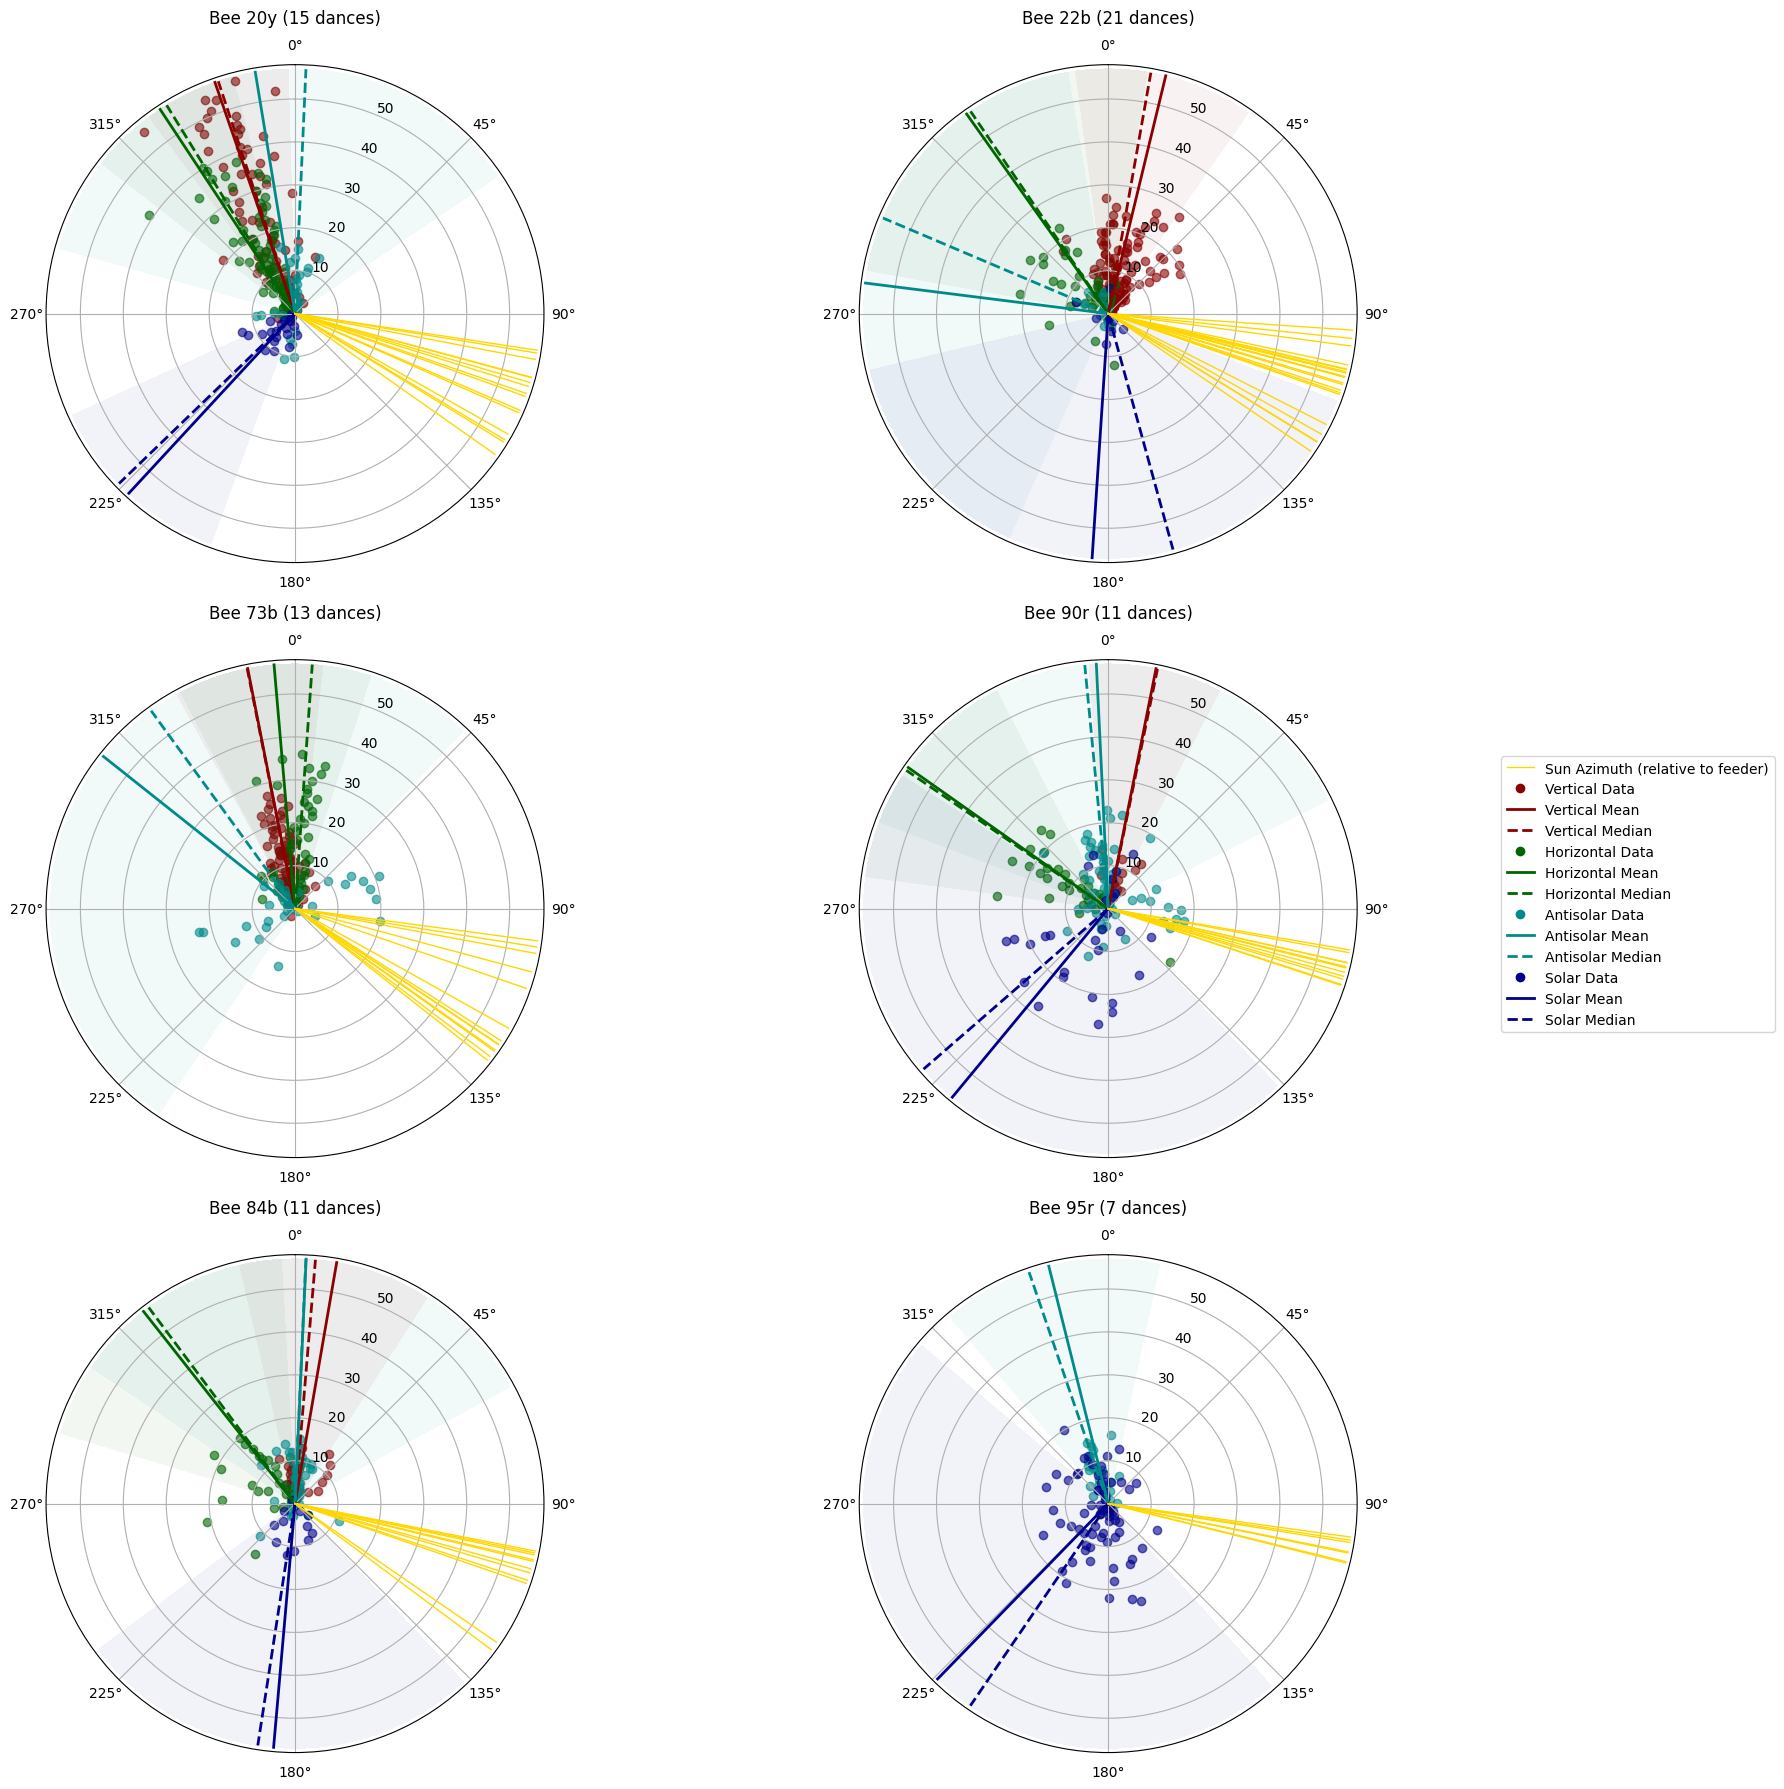

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import circmean, circstd
from matplotlib.lines import Line2D

# Helper function to compute the circular median.
def circ_median(angles):
    angles = np.sort(angles)
    diffs = np.abs(np.angle(np.exp(1j * (angles[:, None] - angles[None, :]))))
    sum_diffs = np.sum(diffs, axis=1)
    return angles[np.argmin(sum_diffs)]

# Helper function to scatter-plot data for one condition.
def plot_scatter(ax, data, angle_col, radial_col, color, label):
    if not data.empty:
        ax.scatter(data[angle_col], data[radial_col],
                   color=color, alpha=0.6, label=label)

# Helper function to compute and plot summary statistics.
# It plots a solid vertical line at the circular mean and a dashed vertical line at the circular median,
# both in the specified color. It also fills the region ± the circular standard deviation.
def plot_summary_stats(ax, angles, radial_max, color):
    # Compute circular mean, median, and standard deviation.
    mean_val = circmean(angles, high=np.pi, low=-np.pi)
    median_val = circ_median(angles)
    std_val = circstd(angles, high=np.pi, low=-np.pi, normalize=True)
    
    # Plot mean (solid) and median (dashed).
    ax.plot([mean_val, mean_val], [0, radial_max], color=color, linewidth=2)
    ax.plot([median_val, median_val], [0, radial_max], color=color, linewidth=2, linestyle='--')
    
    # Fill the region between mean minus std and mean plus std.
    theta_vals = np.linspace(mean_val - std_val, mean_val + std_val, 100)
    r_vals = np.linspace(0, radial_max, 100)
    Theta, R = np.meshgrid(theta_vals, r_vals)
    ax.contourf(Theta, R, np.ones_like(Theta), alpha=0.05, colors=[color]) # was alpha = 0.2, but covers too much data
    
    return mean_val, median_val, std_val

# Colours for each condition, as in HS_ExploratoryPlots.Rmd
cond_cols = {
    'vertical': 'darkred',
    'horizontal': 'darkgreen',
    'antisolar': '#008B8B', # cyan4
    'solar': 'darkblue', # blue4
}

# Select the 6 individuals with the most waggle runs
plot_individuals = df['Individual'].value_counts().index[0:6]

# Create a grid of polar subplots.
n_plots = len(plot_individuals)
n_rows, n_cols = ( np.intc(n_plots/2) , 2  ) # Adjust grid dimensions as needed.
fig, axes = plt.subplots(n_rows, n_cols, subplot_kw={'projection': 'polar'}, figsize=(18, np.intc(n_plots*3)))
axes = axes.flatten()

radial_max = np.max(df['Run'])  # Maximum radial value (maximum runs)

# Plot for each individual.
for idx, individual in enumerate(plot_individuals):
    ax = axes[idx]
    # Set axes to geographic format (clockwise, 0° at the top = feeder direction)
    ax.set_theta_direction(-1)#reverse to clockwise
    ax.set_theta_zero_location('N')#place 0° at the top
    individual_data = df[df['Individual'] == individual]
    
    for cond, col in cond_cols.items():
        # Separate data for each condition (drop NaNs in angle).
        data_c = individual_data[individual_data['condition'] == cond].dropna(subset=['angle'])
        # Scatter-plot data.
        plot_scatter(ax, data_c, 'angle', 'Run', col, cond.capitalize())
        # Plot summary statistics for each condition.
        if not data_c.empty:
            plot_summary_stats(ax, data_c['angle'].values, radial_max, col)
    
    #Plot the sun's azimuth relative to the feeder for each dance, for reference
    for sun_az in individual_data.groupby('Dance')['SunAz'].first():
        ax.plot([sun_az, sun_az], [0, radial_max], color='gold', linewidth=1)
    
    ax.set_title(f"Bee {individual_data['Individual_label'].iloc[0]} "
                 f"({individual_data['Dance'].nunique()} dances)", pad=30)
    ax.set_ylim(0, radial_max + 1)

# Create a shared custom legend.
legend_handles = [
    # For sun azimuth (gold)
    Line2D([0], [0], color = 'gold', lw = 1, label = 'Sun Azimuth (relative to feeder)'),
]
for cond, col in cond_cols.items():
    legend_handles += [
        Line2D([0], [0], marker='o', color='w', markerfacecolor=col, markersize=8, label=f'{cond.capitalize()} Data'),
        Line2D([0], [0], color=col, lw=2, label=f'{cond.capitalize()} Mean'),
        Line2D([0], [0], color=col, lw=2, linestyle='--', label=f'{cond.capitalize()} Median'),
    ]

# Add one shared legend to the right of the figure.
fig.legend(handles=legend_handles, loc='center right', bbox_to_anchor=(1.10, 0.5), fontsize='medium')

plt.tight_layout()
plt.show()

# Fit a circular model with all potential effects
First fit the maximal model with effects of condition on both mean direction ($\mu$) and directional consistency ($\kappa$), with the vertical condition as the reference (Intercept) and successive effects of horizontal orientation (H), antisolar skylight (A) and solar skylight (S).
Individuals may have danced in several conditions, so they receive random intercepts and random effects of each condition.
Each dance was performed in a single condition, so dances (nested within individuals) receive random intercepts only.

$\mu \sim$ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)

$\kappa \sim$ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)

The priors follow `HS_circGLMM_fit.ipynb`, with the priors for the condition effect also applied to the antisolar and solar effects.
*N.B.* the antisolar and solar conditions include only 8 and 7 individuals respectively, so their individual-level effects are informed by few individuals.

In [6]:
import numpy as np
import pandas as pd
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt

from unwrap.link.bambi import LINKS
from unwrap.link.numpy import inverse_softplus
from unwrap.prior import CircularUniformPrior
from pymc import VonMises
from scipy.stats import vonmises, circstd

# Define the model formula.
formula_condition = bmb.Formula(
    "angle ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)",
    "kappa ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)",
)

# Shared prior components, following HS_circGLMM_fit.ipynb
# Fixed effects of condition for μ: weak, centred on no change
prior_mu_effect = bmb.Prior("VonMises", mu=0, kappa=0.5) # Test
# Individual-level effects for μ: informative prior, individuals close to pop mean circsd ~10°
prior_mu_ind = bmb.Prior(
    "VonMises", mu=0, kappa=bmb.Prior("LogNormal", mu=np.log(30), sigma=0.60)
)
# Fixed effects of condition for κ
prior_kappa_effect = bmb.Prior("Normal", mu=0, sigma=1.0) # Test
# Individual-level effects for κ
prior_kappa_ind = bmb.Prior(
    "Normal", mu=0, sigma=bmb.Prior("HalfStudentT", nu=3, sigma=1.0)
)

# Specify priors for the model.
priors_condition = {
    # Fixed effects for μ:
    "Intercept": CircularUniformPrior(), # Test
    "H": prior_mu_effect,
    "A": prior_mu_effect,
    "S": prior_mu_effect,
    # Individual-level effects for μ:
    "1|Individual": prior_mu_ind,
    "H|Individual": prior_mu_ind,
    "A|Individual": prior_mu_ind,
    "S|Individual": prior_mu_ind,
    # Dance-level effects for μ: same informative prior, dances close to individual mean
    "1|Dance": prior_mu_ind, # Test
    # Priors for the κ-model (inside the "kappa" dictionary):
    "kappa": {
        # Fixed effects for κ:
        "Intercept": bmb.Prior("Normal", mu=inverse_softplus(3), sigma=3.0),
        "H": prior_kappa_effect,
        "A": prior_kappa_effect,
        "S": prior_kappa_effect,
        # Individual-level effects for κ:
        "1|Individual": prior_kappa_ind,
        "H|Individual": prior_kappa_ind,
        "A|Individual": prior_kappa_ind,
        "S|Individual": prior_kappa_ind,
        # Dance-level effects for κ:
        "1|Dance": prior_kappa_ind, # Test
    }
}

# Build the model using the formula and priors.
model_condition = bmb.Model(
    formula_condition,
    df,
    family="vonmises",
    priors=priors_condition,
    link={"mu": LINKS["shifted_modulo"], "kappa": LINKS["softplus"]},
    center_predictors=False,
    dropna=True,
)

print(model_condition)

# Fit the model using Bambi's native nutpie interface
idata_condition = model_condition.fit(
    draws=2000,
    tune=1000,
    nuts_sampler="nutpie",  #build and route via nutpie automatically
    target_accept=0.98
)

# Save model.
os.makedirs("2Results", exist_ok=True)
az.to_netcdf(idata_condition, "2Results/HS_unwrap_4cond.nc")

       Formula: angle ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)
                kappa ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)
        Family: vonmises
          Link: mu = shifted_modulo
                kappa = softplus
  Observations: 1418
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ CircularUniform()
            H ~ VonMises(mu: 0.0, kappa: 0.5)
            A ~ VonMises(mu: 0.0, kappa: 0.5)
            S ~ VonMises(mu: 0.0, kappa: 0.5)
        
        Group-level effects
            1|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 3.4012, sigma: 0.6))
            H|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 3.4012, sigma: 0.6))
            A|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 3.4012, sigma: 0.6))
            S|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 3.4012, sigma: 0.6))
            1|Dance ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 3.4012, sigma: 0.6))
    target = kappa
   

/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/pymc/sampling/mcmc.py:303: UserWarning: `var_names` are currently ignored by the nutpie sampler
  warnings.warn(


Progress,Draws,Divergences,Step Size,Gradients/Draw
,3000,0,0.04,255
,3000,0,0.04,255
,3000,0,0.05,127
,3000,0,0.04,127


'2Results/HS_unwrap_4cond.nc'

## Check convergence heuristics

In [7]:
#check convergence heuristics
az.summary(
    idata_condition, 
    var_names=["Intercept",
               "H", 
               "S", 
               "A", 
               "kappa_Intercept",
               "kappa_H",
               "kappa_S",
               "kappa_A",
                ],
    circ_var_names=["Intercept",
                    "H",
                    "S",
                    "A",
                    ]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.088,0.065,-0.038,0.210,0.002,0.001,1755.0,2655.0,1.0
H,-0.437,0.101,-0.629,-0.254,0.002,0.002,1819.0,3224.0,1.0
S,-2.415,0.229,-2.847,-1.980,0.003,0.003,3150.0,3851.0,1.0
A,0.186,0.183,-0.164,0.526,0.006,0.004,1056.0,2321.0,1.0
kappa_Intercept,13.913,1.594,10.905,16.879,0.062,0.044,661.0,1971.0,1.0
kappa_H,-0.698,0.952,-2.574,1.009,0.015,0.010,4302.0,5306.0,1.0
kappa_S,-0.674,0.966,-2.413,1.165,0.011,0.009,7591.0,6471.0,1.0
kappa_A,-1.224,1.058,-3.154,0.837,0.029,0.020,1379.0,3186.0,1.0


In [8]:
#check convergence heuristics on random effects
az.summary(
    idata_condition, 
    var_names=[
        "1|Individual_kappa",
        "H|Individual_kappa",
        "S|Individual_kappa",
        "A|Individual_kappa",
        "1|Dance_kappa",
        "kappa_1|Individual_sigma",
        "kappa_H|Individual_sigma",
        "kappa_S|Individual_sigma",
        "kappa_A|Individual_sigma",
        "kappa_1|Dance_sigma",
                ],
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|Individual_kappa,46.777,24.611,12.123,89.116,0.519,0.367,2056.0,4006.0,1.00
H|Individual_kappa,30.462,19.816,6.391,64.655,0.579,0.409,1139.0,2546.0,1.00
S|Individual_kappa,36.372,23.821,6.673,77.422,0.630,0.446,1238.0,2175.0,1.00
A|Individual_kappa,23.192,17.681,2.809,53.946,0.639,0.452,531.0,1189.0,1.01
1|Dance_kappa,11.735,2.412,7.578,16.411,0.056,0.040,1753.0,3863.0,1.00
kappa_1|Individual_sigma,1.290,1.184,0.000,3.456,0.032,0.022,1396.0,2052.0,1.00
kappa_H|Individual_sigma,0.981,0.907,0.000,2.558,0.018,0.012,2383.0,2283.0,1.00
kappa_S|Individual_sigma,1.175,1.294,0.000,3.381,0.024,0.017,3201.0,2489.0,1.00
kappa_A|Individual_sigma,4.899,5.350,0.010,14.547,0.404,0.286,183.0,850.0,1.02
kappa_1|Dance_sigma,11.349,2.021,7.734,15.134,0.105,0.074,298.0,946.0,1.02


## Visualise output of the model

- The "Intercept" is the condition: **Vertical**
- H is the effect of horizontal orientation: **Horizontal** = Intercept + H
- A is the effect of antisolar skylight: **Antisolar** = Intercept + H + A
- S is the effect of solar skylight: **Solar** = Intercept + H + A + S

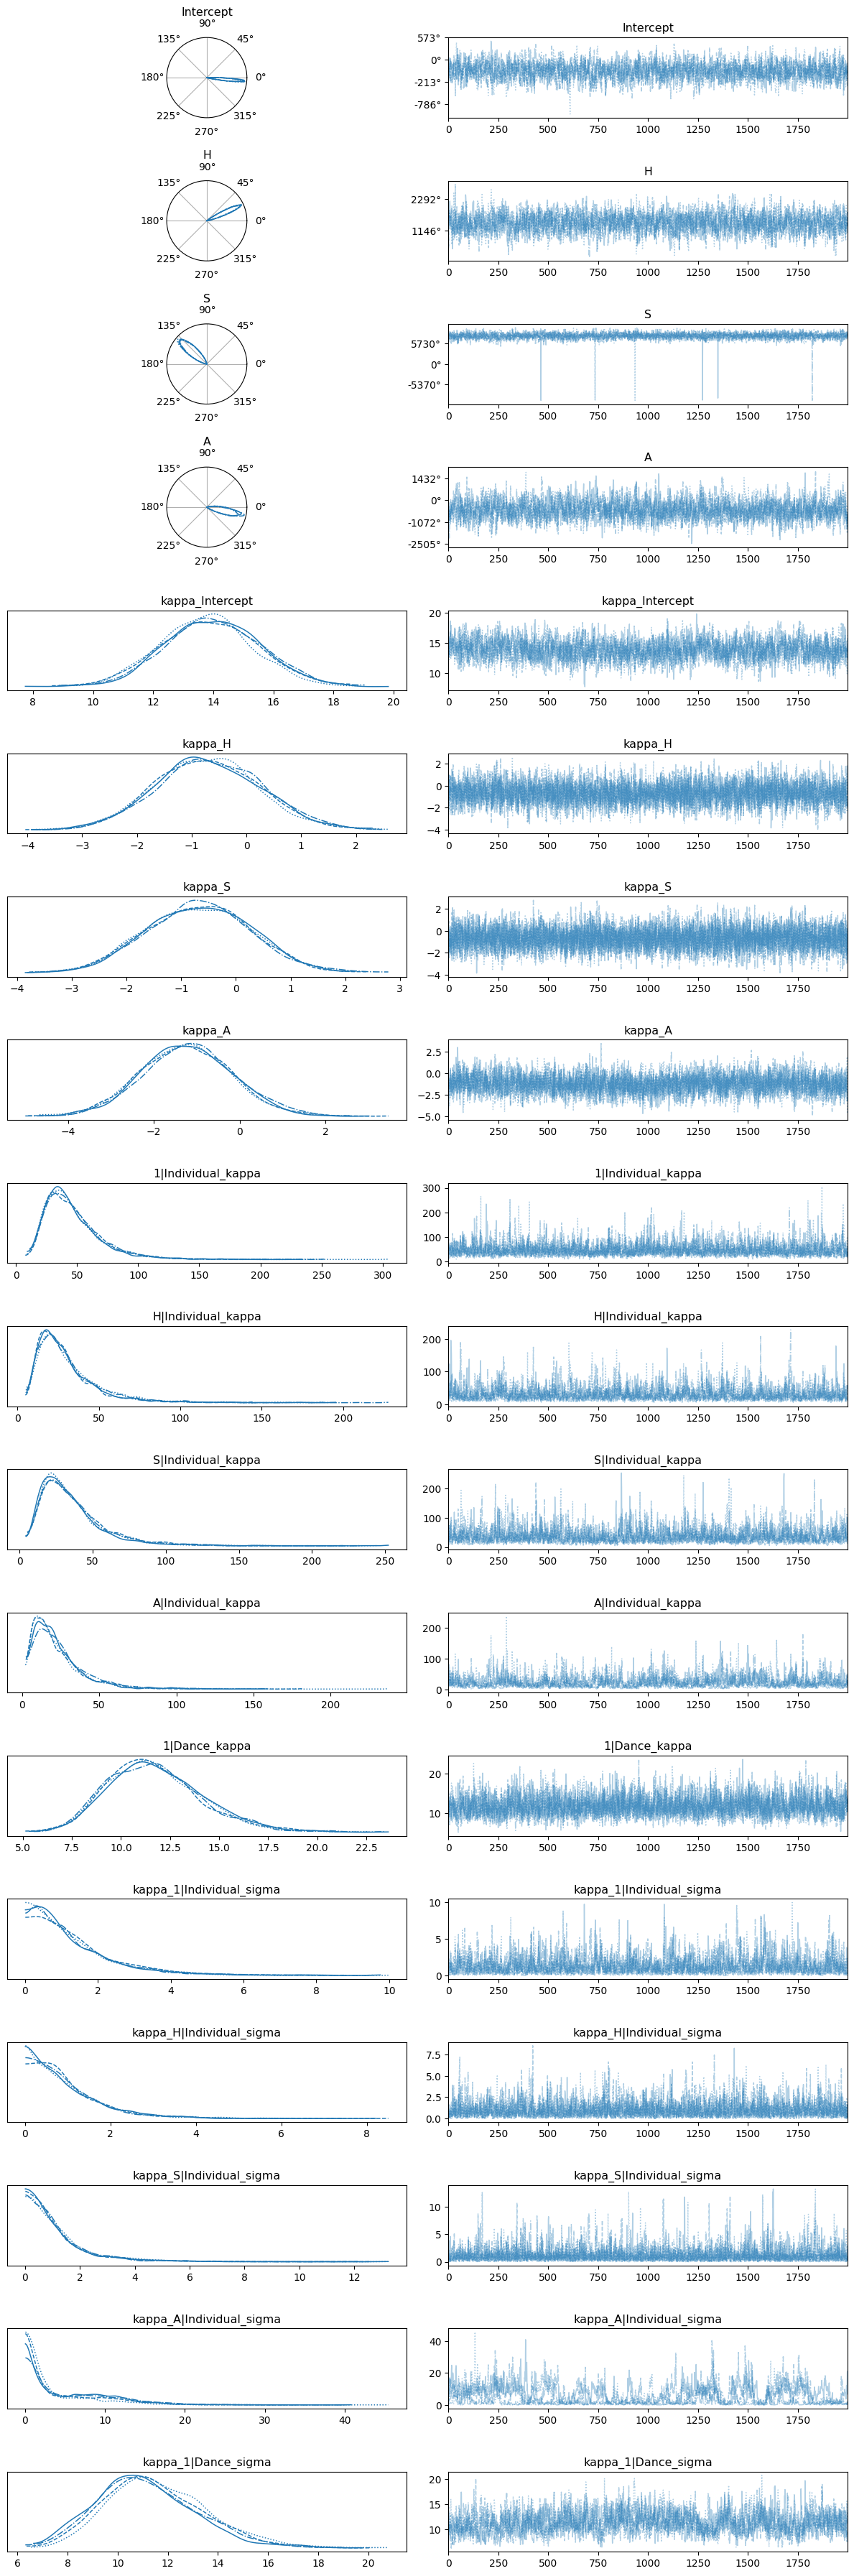

In [9]:
plot_circular_trace(
                    idata = idata_condition,
                    vars=[
                            "Intercept",
                            "H",
                            "S",
                            "A",
                            "kappa_Intercept",
                            "kappa_H",
                            "kappa_S",
                            "kappa_A",
                            "1|Individual_kappa",
                            "H|Individual_kappa",
                            "S|Individual_kappa",
                            "A|Individual_kappa",
                            "1|Dance_kappa",
                            "kappa_1|Individual_sigma",
                            "kappa_H|Individual_sigma",
                            "kappa_S|Individual_sigma",
                            "kappa_A|Individual_sigma",
                            "kappa_1|Dance_sigma",
                        ],
                    cvars = ["Intercept",
                            "H",
                            "S",
                            "A",
                            ]
)

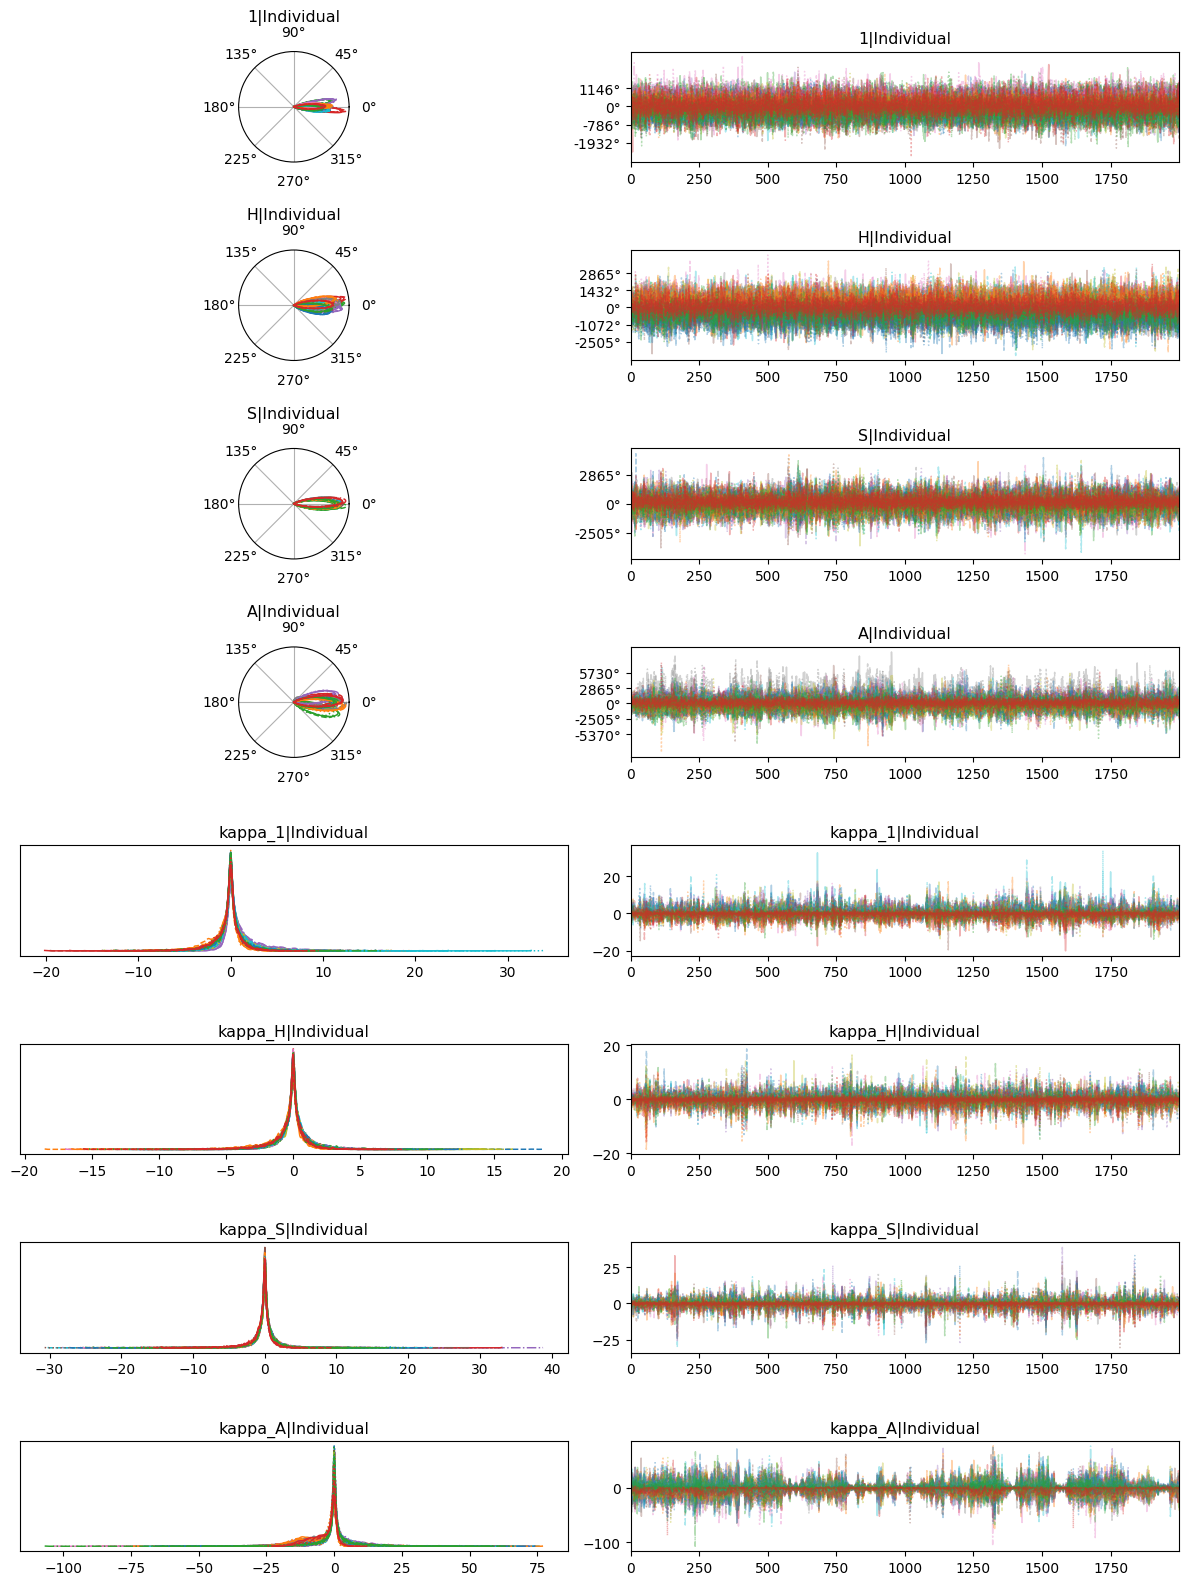

In [10]:
plot_circular_trace(
                    idata = idata_condition,
vars=[
        "1|Individual",
        "H|Individual",
        "S|Individual",
        "A|Individual",
        "kappa_1|Individual",
        "kappa_H|Individual",
        "kappa_S|Individual",
        "kappa_A|Individual",
       ],
cvars = [
        "1|Individual",
        "H|Individual",
        "S|Individual",
        "A|Individual",
        ]
)

# Loosen the individual-level prior
The prior on the concentration of individual mean directions (LogNormal(log 30, 0.6)) places very little probability below $\kappa_\mu \approx 10$, which may shrink individuals that differ substantially from the population mean (e.g. 60r, 69r, 73b, 94w) too strongly towards it.
Here we fit the same model with a looser prior, LogNormal(log 10, 1), for all individual-level effects on $\mu$ (median $\kappa_\mu = 10$, 95% interval 1.4–71), leaving the $\kappa$ priors unchanged.
The prior on dances within each individual (`1|Dance`) is kept restrictive (LogNormal(log 30, 0.6)), since most individuals performed few dances per condition, and an individual's dances in different conditions are already separated by the condition effects.

In [11]:
# Looser prior for individual-level effects on μ
prior_mu_ind_wide = bmb.Prior(
    "VonMises", mu=0, kappa=bmb.Prior("LogNormal", mu=np.log(10), sigma=1.0)
)

priors_condition_wide = dict(priors_condition)
for term in ["1|Individual", "H|Individual", "A|Individual", "S|Individual"]:
    priors_condition_wide[term] = prior_mu_ind_wide
# N.B. "1|Dance" keeps the restrictive prior from priors_condition

# Build the model using the same formula and data.
model_condition_wide = bmb.Model(
    formula_condition,
    df,
    family="vonmises",
    priors=priors_condition_wide,
    link={"mu": LINKS["shifted_modulo"], "kappa": LINKS["softplus"]},
    center_predictors=False,
    dropna=True,
)

print(model_condition_wide)

# Fit the model using Bambi's native nutpie interface
idata_condition_wide = model_condition_wide.fit(
    draws=2000,
    tune=1000,
    nuts_sampler="nutpie",  #build and route via nutpie automatically
    target_accept=0.98
)

# Save model.
az.to_netcdf(idata_condition_wide, "2Results/HS_unwrap_4cond_wideInd.nc")

       Formula: angle ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)
                kappa ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)
        Family: vonmises
          Link: mu = shifted_modulo
                kappa = softplus
  Observations: 1418
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ CircularUniform()
            H ~ VonMises(mu: 0.0, kappa: 0.5)
            A ~ VonMises(mu: 0.0, kappa: 0.5)
            S ~ VonMises(mu: 0.0, kappa: 0.5)
        
        Group-level effects
            1|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 2.3026, sigma: 1.0))
            H|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 2.3026, sigma: 1.0))
            A|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 2.3026, sigma: 1.0))
            S|Individual ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 2.3026, sigma: 1.0))
            1|Dance ~ VonMises(mu: 0.0, kappa: LogNormal(mu: 3.4012, sigma: 0.6))
    target = kappa
   

/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/pymc/sampling/mcmc.py:303: UserWarning: `var_names` are currently ignored by the nutpie sampler
  warnings.warn(


Progress,Draws,Divergences,Step Size,Gradients/Draw
,3000,0,0.04,127
,3000,0,0.04,255
,3000,1,0.04,127
,3000,0,0.04,127


'2Results/HS_unwrap_4cond_wideInd.nc'

In [12]:
#check convergence heuristics
az.summary(
    idata_condition_wide, 
    var_names=["Intercept", "H", "A", "S",
               "kappa_Intercept", "kappa_H", "kappa_A", "kappa_S",
               "1|Individual_kappa", "H|Individual_kappa", "A|Individual_kappa", "S|Individual_kappa",
               "1|Dance_kappa",
               "kappa_1|Individual_sigma", "kappa_H|Individual_sigma",
               "kappa_A|Individual_sigma", "kappa_S|Individual_sigma",
               "kappa_1|Dance_sigma",
                ],
    circ_var_names=["Intercept", "H", "A", "S"]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.088,0.068,-0.039,0.220,0.003,0.002,975.0,1833.0,1.01
H,-0.402,0.122,-0.626,-0.165,0.003,0.003,1105.0,1325.0,1.00
A,0.137,0.293,-0.387,0.729,0.011,0.008,735.0,1115.0,1.01
S,-2.500,0.259,-2.975,-2.006,0.005,0.008,2019.0,2908.0,1.00
kappa_Intercept,13.949,1.530,11.152,16.843,0.062,0.044,615.0,2204.0,1.00
kappa_H,-0.734,0.970,-2.545,1.094,0.018,0.013,2834.0,4008.0,1.00
kappa_A,-1.237,1.078,-3.232,0.835,0.030,0.021,1278.0,3632.0,1.00
kappa_S,-0.667,0.966,-2.590,1.084,0.014,0.011,5015.0,4674.0,1.00
1|Individual_kappa,39.898,28.264,8.055,86.557,0.778,0.550,1255.0,2201.0,1.00
H|Individual_kappa,13.654,11.551,2.630,31.928,0.370,0.262,902.0,1502.0,1.00


## Compare individual-level priors
Compare the predictive performance (LOO-CV) of the two priors.

In [13]:
# Manually compute and attach the log-likelihood group to the existing idata
model_condition.compute_log_likelihood(idata_condition)
model_condition_wide.compute_log_likelihood(idata_condition_wide)

loo_condition = az.loo(idata_condition)
loo_condition_wide = az.loo(idata_condition_wide)

comparison_prior = az.compare(
    {
    'Condition (strict individual prior)': loo_condition,
    'Condition (wide individual prior)': loo_condition_wide,
    },
    ic="loo")
print(comparison_prior.round(2))

/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:1039: RuntimeWarning: overflow encountered in exp
  weights = 1 / np.exp(len_scale - len_scale[:, None]).sum(axis=1)


/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:792: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:1039: RuntimeWarning: overflow encountered in exp
  weights = 1 / np.exp(len_scale - len_scale[:, None]).sum(axis=1)


/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:792: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


                                     rank  elpd_loo   p_loo  elpd_diff  \
Condition (wide individual prior)       0   -675.34  195.25       0.00   
Condition (strict individual prior)     1   -681.13  196.70       5.79   

                                     weight     se  dse  warning scale  
Condition (wide individual prior)      0.96  48.52  0.0     True   log  
Condition (strict individual prior)    0.04  48.59  3.5     True   log  


The alternative models below use the individual-level prior selected here (`priors_ind_selected`).

In [14]:
# Individual-level μ priors for the alternative models
priors_ind_selected = priors_condition_wide # or priors_condition for the strict prior

# Alternative Hypotheses
We would like to test whether condition affects dance direction and accuracy:
0. Are all data explained by individual and dance differences alone?
    - $\mu \sim$ 1
    - $\kappa \sim$ 1
1. Does condition affect accuracy, but not mean direction?
    - $\mu \sim$ 1
    - $\kappa \sim$ condition
2. Does condition affect both mean direction and accuracy?
    - $\mu \sim$ condition
    - $\kappa \sim$ condition
    - (already fitted, with strict and wide individual-level priors)

In [15]:
#model 0
formula_null = bmb.Formula(
    "angle ~ 1 + (1 |Individual) + (1 |Dance)",
    "kappa ~ 1 + (1 |Individual) + (1 |Dance)",
)

#model 1
formula_conditionKappa = bmb.Formula(
    "angle ~ 1 + (1 |Individual) + (1 |Dance)",
    "kappa ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)",
)

#models 2 (strict) and 3 (wide) already fitted
    # "angle ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)",
    # "kappa ~ H + A + S + (1 + H + A + S |Individual) + (1 |Dance)",

# =============================================================================
# 0. MODEL NULL PRIORS
# =============================================================================
priors_null = {
    "Intercept": bmb.Prior("VonMises", mu=0, kappa=1.0), # weak bias to the feeder direction (0°)
    "1|Individual": priors_ind_selected["1|Individual"],
    "1|Dance": priors_condition["1|Dance"],
    "kappa": {
        "Intercept": priors_condition["kappa"]["Intercept"],
        "1|Individual": priors_condition["kappa"]["1|Individual"],
        "1|Dance": priors_condition["kappa"]["1|Dance"],
    }
}

# =============================================================================
# 1. MODEL CONDITION-KAPPA PRIORS
# =============================================================================
priors_conditionKappa = {
    "Intercept": priors_null["Intercept"],
    "1|Individual": priors_ind_selected["1|Individual"],
    "1|Dance": priors_condition["1|Dance"],
    "kappa": priors_condition["kappa"],
}

#model 0
model_null = bmb.Model(
    formula_null,
    df,
    family="vonmises",
    priors=priors_null,
    link={"mu": LINKS["shifted_modulo"], "kappa": LINKS["softplus"]},
    center_predictors=False,
    dropna=True,
)

#model 1
model_conditionKappa = bmb.Model(
    formula_conditionKappa,
    df,
    family="vonmises",
    priors=priors_conditionKappa,
    link={"mu": LINKS["shifted_modulo"], "kappa": LINKS["softplus"]},
    center_predictors=False,
    dropna=True,
)

## Run Null model (0)
Null (Intercept, Individual-level and Dance-level random intercepts only)

In [16]:
# Fit the model.
idata_null = model_null.fit(
    draws=2000,
    tune=1000,
    progressbar="split+stats",
    nuts_sampler="nutpie",  # build and route via nutpie automatically
    target_accept=0.98
)

# check convergence heuristics for fixed/population effects
az.summary(
    idata_null, 
    var_names=[
        "Intercept", 
        "kappa_Intercept",
        "1|Individual_kappa",
        "1|Dance_kappa",
        "kappa_1|Individual_sigma",
        "kappa_1|Dance_sigma",
    ],
    circ_var_names=[
        "Intercept",
    ]
)

/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/pymc/sampling/mcmc.py:303: UserWarning: `var_names` are currently ignored by the nutpie sampler
  warnings.warn(


Progress,Draws,Divergences,Step Size,Gradients/Draw
,3000,0,0.05,255
,3000,0,0.06,255
,3000,0,0.06,63
,3000,0,0.06,255


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.173,0.085,-0.331,-0.016,0.002,0.002,1257.0,2499.0,1.00
kappa_Intercept,12.196,1.600,9.058,15.124,0.053,0.038,904.0,1997.0,1.00
1|Individual_kappa,25.132,23.155,3.704,57.612,0.899,0.641,875.0,1172.0,1.00
1|Dance_kappa,4.301,0.894,2.785,6.004,0.118,0.084,59.0,377.0,1.06
kappa_1|Individual_sigma,1.836,1.879,0.000,5.306,0.072,0.051,733.0,1337.0,1.01
kappa_1|Dance_sigma,15.069,2.153,11.188,19.113,0.090,0.063,553.0,2025.0,1.01


## Run condition-kappa model (1)
$\mu$ no effects, $\kappa$ condition

In [17]:
# Fit the model.
idata_conditionKappa = model_conditionKappa.fit(
    draws=2000,
    tune=1000,
    progressbar="split+stats",
    nuts_sampler="nutpie",  # build and route via nutpie automatically
    target_accept=0.98
)

az.summary(
    idata_conditionKappa, 
    var_names=[
        "Intercept", 
        "kappa_Intercept",
        "kappa_H",
        "kappa_S",
        "kappa_A",
        "1|Individual_kappa",
        "1|Dance_kappa",
        "kappa_1|Individual_sigma",
        "kappa_H|Individual_sigma",
        "kappa_S|Individual_sigma",
        "kappa_A|Individual_sigma",
        "kappa_1|Dance_sigma",
    ],
    circ_var_names=[
        "Intercept",
    ]
)

/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/pymc/sampling/mcmc.py:303: UserWarning: `var_names` are currently ignored by the nutpie sampler
  warnings.warn(


Progress,Draws,Divergences,Step Size,Gradients/Draw
,3000,1,0.04,127
,3000,0,0.04,511
,3000,0,0.04,127
,3000,0,0.04,127


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.170,0.085,-0.336,-0.015,0.003,0.002,707.0,1166.0,1.01
kappa_Intercept,14.357,1.655,11.229,17.518,0.076,0.054,467.0,1492.0,1.01
kappa_H,-0.524,0.962,-2.298,1.334,0.019,0.013,2691.0,4062.0,1.00
kappa_S,-0.791,0.988,-2.606,1.120,0.013,0.009,5588.0,5973.0,1.00
kappa_A,-0.969,1.075,-2.986,1.022,0.028,0.020,1452.0,4105.0,1.01
1|Individual_kappa,24.506,18.621,4.240,54.125,0.707,0.500,692.0,1128.0,1.00
1|Dance_kappa,4.583,0.886,2.876,6.148,0.095,0.068,79.0,227.0,1.06
kappa_1|Individual_sigma,1.409,1.415,0.000,3.889,0.049,0.035,838.0,1061.0,1.01
kappa_H|Individual_sigma,1.000,0.944,0.000,2.599,0.023,0.017,1416.0,1486.0,1.01
kappa_S|Individual_sigma,2.448,4.853,0.001,9.172,0.273,0.193,470.0,426.0,1.01


## Save all models

In [18]:
# Ensure the results directory exists before saving
os.makedirs("2Results/unwrap_models", exist_ok=True)

# Dictionary mapping our fitted InferenceData objects to their descriptive filenames
models_to_save = {
    "model_0_null": idata_null,
    "model_1_conditionKappa": idata_conditionKappa,
    "model_2_condition": idata_condition,  # Already fitted
    "model_3_condition_wideInd": idata_condition_wide,  # Already fitted
}

# Systematically export each model to NetCDF format
for file_prefix, idata_obj in models_to_save.items():
    save_path = f"2Results/unwrap_models/HS_4cond_unwrap_{file_prefix}.nc"
    print(f"Exporting: {save_path}...")
    az.to_netcdf(idata_obj, save_path)

Exporting: 2Results/unwrap_models/HS_4cond_unwrap_model_0_null.nc...


Exporting: 2Results/unwrap_models/HS_4cond_unwrap_model_1_conditionKappa.nc...


Exporting: 2Results/unwrap_models/HS_4cond_unwrap_model_2_condition.nc...


Exporting: 2Results/unwrap_models/HS_4cond_unwrap_model_3_condition_wideInd.nc...


# Model comparison for hypothesis testing
## LOO-CV
Leave one out cross validation (LOO-CV) to calculate estimated log predictive density for each model (ELPD).

/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:1039: RuntimeWarning: overflow encountered in exp
  weights = 1 / np.exp(len_scale - len_scale[:, None]).sum(axis=1)


/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:792: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:1039: RuntimeWarning: overflow encountered in exp
  weights = 1 / np.exp(len_scale - len_scale[:, None]).sum(axis=1)


/opt/miniconda3/envs/HS-env/lib/python3.12/site-packages/arviz/stats/stats.py:792: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(



----- Model Comparison Ranking -----

                                     rank  elpd_loo   p_loo  elpd_diff  \
Condition (wide individual prior)       0   -675.34  195.25       0.00   
Condition (strict individual prior)     1   -681.13  196.70       5.79   
No effects                              2   -692.38  215.10      17.03   
Condition kappa                         3   -703.44  206.99      28.10   

                                     weight     se   dse  warning scale  
Condition (wide individual prior)      0.81  48.52  0.00     True   log  
Condition (strict individual prior)    0.02  48.59  3.50     True   log  
No effects                             0.17  48.96  7.43     True   log  
Condition kappa                        0.00  48.73  7.55     True   log  


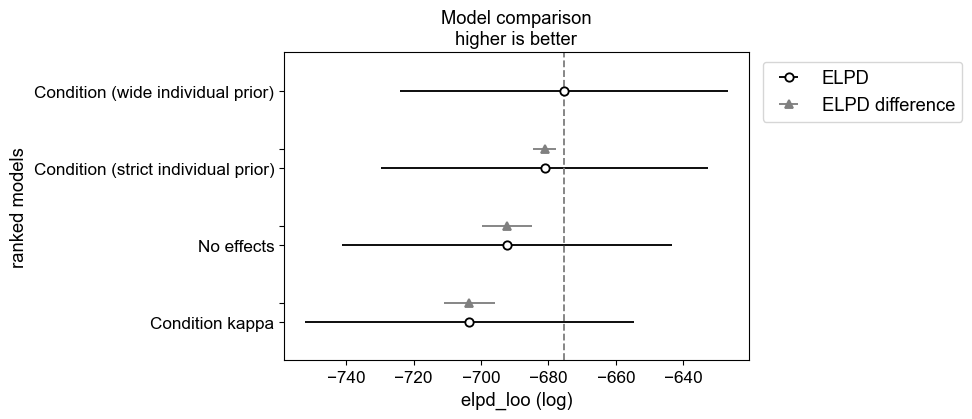

In [19]:
import matplotlib as mpl

# Manually compute and attach the log-likelihood group to the existing idata
# (already computed for the maximal models above)
model_null.compute_log_likelihood(idata_null)
model_conditionKappa.compute_log_likelihood(idata_conditionKappa)

# Compute LOO
loo_null = az.loo(idata_null)
loo_conditionKappa = az.loo(idata_conditionKappa)

# Compare, ranking models from best to worst
comparison = az.compare(
    {
    'No effects': loo_null,
    'Condition kappa': loo_conditionKappa,
    'Condition (strict individual prior)': loo_condition,
    'Condition (wide individual prior)': loo_condition_wide,
    },
    ic="loo")

print('\n----- Model Comparison Ranking -----\n')
print(comparison.round(2))

# Ensure text is output as editable TrueType text elements in PDFs
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Computer Modern Sans Serif']

# Visualize the comparison
ax_compare = az.plot_compare(comparison)
fig_compare = ax_compare.get_figure()
fig_compare.savefig("Plots/HS_4cond_model_comparison.pdf", format="pdf", bbox_inches="tight")

# Extract & inspect posterior samples from maximal model
Using the maximal model with the selected individual-level prior.

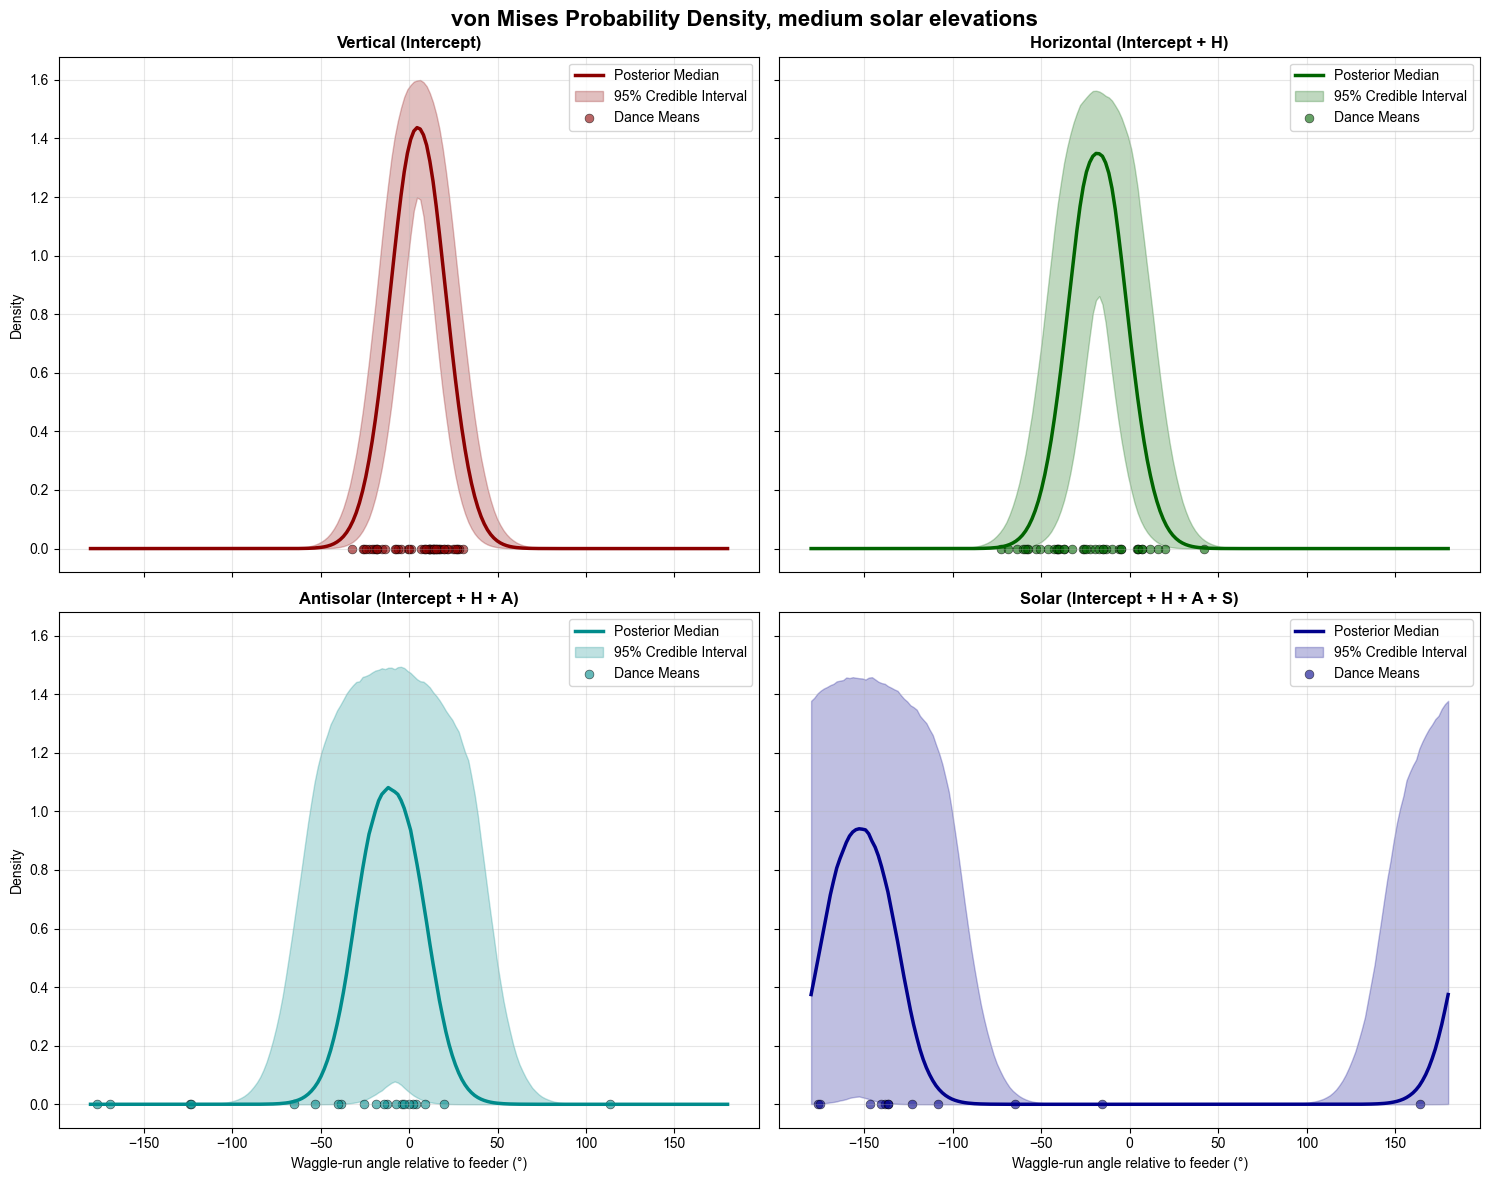

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import vonmises, circmean
from unwrap.link.numpy import shifted_modulo, softplus

# --------------------------------------------------
# Extract posterior samples for population-level parameters
# --------------------------------------------------
idata_selected = idata_condition_wide if priors_ind_selected is priors_condition_wide else idata_condition
post = idata_selected.posterior
mu_intercept    = post['Intercept'].values.flatten()
kappa_intercept = post['kappa_Intercept'].values.flatten()

# Successive effects for each condition (vertical is the reference)
effects = {'vertical': [], 'horizontal': ['H'], 'antisolar': ['H', 'A'], 'solar': ['H', 'A', 'S']}
mu_pop = {}
kappa_pop = {}
for cond, effs in effects.items():
    mu_pop[cond] = shifted_modulo(mu_intercept + sum(post[e].values.flatten() for e in effs))
    kappa_pop[cond] = softplus(kappa_intercept + sum(post['kappa_' + e].values.flatten() for e in effs))

# --------------------------------------------------
# Prepare data grid
# --------------------------------------------------
theta = np.linspace(-np.pi, np.pi, 200)
theta_deg = theta * 180 / np.pi

# --------------------------------------------------
# Setup 2x2 Subplot Grid
# --------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True)

for ax, (cond, effs) in zip(axes.flat, effects.items()):
    # Compute von Mises PDFs
    pdf = vonmises.pdf(theta[None, :], kappa=kappa_pop[cond][:, None], loc=mu_pop[cond][:, None])
    # Plot density and 95% Credible Intervals (2.5% to 97.5%)
    ax.plot(theta_deg, np.median(pdf, axis=0), color=cond_cols[cond], lw=2.5, label="Posterior Median")
    ax.fill_between(theta_deg,
                    np.percentile(pdf, 2.5, axis=0),
                    np.percentile(pdf, 97.5, axis=0),
                    color=cond_cols[cond], alpha=0.25, label="95% Credible Interval")
    ax.set_title(f"{cond.capitalize()} (Intercept{''.join(' + ' + e for e in effs)})",
                 fontsize=12, fontweight="bold")
    ax.grid(True, alpha=0.3)

    # Calculate and overlay dance summary means
    dance_means = (df[df['condition'] == cond]
                   .dropna(subset=['angle'])
                   .groupby('Dance')['angle']
                   .apply(lambda x: shifted_modulo(circmean(x, high=np.pi, low=-np.pi))))
    ax.scatter(
        dance_means * 180 / np.pi, np.zeros(len(dance_means)), 
        color=cond_cols[cond], edgecolor='black', linewidth=0.5, 
        s=40, alpha=0.6, 
        label='Dance Means'
    )

# Global formatting details
for ax in axes.flat:
    ax.set_xlabel('Waggle-run angle relative to feeder (°)')
    ax.set_ylabel('Density')
    ax.label_outer() # Hides inner labels to avoid overlap clutter
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.8)

plt.suptitle('von Mises Probability Density, medium solar elevations', fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()